In [19]:
import pandas as pd


default_file_path = "../../data/raw/"
save_file_path = "../../data/iterim/"


def convert_integer_column(df_column: pd.Series):
    converted_column = df_column.astype("string").str.replace(" ", "", regex=False).str.replace(",", ".", regex=False).str.replace("\u00a0", "", regex=False).str.replace("—", "-", regex=False)
    converted_column = pd.to_numeric(converted_column, errors="coerce")
    return converted_column.round(2)


def convert_datetime_column(df_column: pd.Series):
    converted_column = pd.to_datetime(df_column, errors="coerce", format="mixed")
    return converted_column


def convert_string_column(df_column: pd.Series):
    convert_column = df_column.astype("string").str.lower().str.strip().str.replace(" ", "_")
    return convert_column

In [37]:
df = pd.read_csv(f"{default_file_path}wells.csv")
df_concentration = pd.read_csv(f"{default_file_path}concentration.csv")
df_cores = pd.read_csv(f"{default_file_path}cores.csv")
df_head = pd.read_csv(f"{default_file_path}head.csv")

In [21]:
display(df)
display(df.info())
display(df.describe())

,well_id,x,y,z,role,zone,commissioned
0,BH-084,569.69,1741.66,NaN,monitoring,Industrial_Zone,2018-04-25
1,BH-271,2199.55,255.93,-11.41,monitoring,Central_Zone,29.10.2018
2,BH-243,3476.6,2001.54,-10.85,monitoring,Water_Intake_Zone,2018-10-01
3,BH-166,2044.9,1235.17,-20.01,monitoring,Central_Zone,16.07.2018
4,BH-167,2447.4,"1 551,83",-48.09,monitoring,Central_Zone,2018-07-17
...,...,...,...,...,...,...,...
323,BH-233,3673.47,1638.95,-8.14,monitoring,Water_Intake_Zone,2018-09-21
324,BH-024,403.67,1888.58,-21.57,monitoring,Industrial_Zone,2018-02-24
325,BH-139,2573.18,1254.71,-28.88,monitoring,Central_Zone,2018-06-19
326,BH-025,1419.3,1321.91,-50.37,monitoring,Central_Zone,2018-02-25


<class 'pandas.DataFrame'>
RangeIndex: 328 entries, 0 to 327
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   well_id       328 non-null    str  
 1   x             317 non-null    str  
 2   y             328 non-null    str  
 3   z             321 non-null    str  
 4   role          328 non-null    str  
 5   zone          320 non-null    str  
 6   commissioned  328 non-null    str  
dtypes: str(7)
memory usage: 37.1 KB


None

,well_id,x,y,z,role,zone,commissioned
count,328,317,328,321,328,320,328
unique,321,310,310,313,4,3,323
top,BH-022,716.17,-999.0,-34.66,monitoring,Central_Zone,2018-02-24
freq,2,2,14,2,310,131,2


In [22]:
df["x"] = convert_integer_column(df["x"])
df["y"] = convert_integer_column(df["y"])
df["z"] = convert_integer_column(df["z"])

df["role"] = convert_string_column(df["role"])

df["commissioned"] = convert_string_column(df["commissioned"])

In [36]:
nan_mask = df.loc[(df["x"].isna()) | (df["y"].isna()) | (df["z"].isna()) | (df["commissioned"].isna()), "well_id"]

df_concentration = df_concentration[~df_concentration["well_id"].isin(nan_mask)]
df_cores = df_cores[~df_cores["well_id"].isin(nan_mask)]
df_head = df_head[~df_head["well_id"].isin(nan_mask)]


,sample_id,well_id,concentration,lod,quality,t,result_version,unit,lab
0,LAB-000272,BH-105,0.933,0.05,ok,19.03.2024,1,ug/L,LAB-A
1,LAB-001351,BH-047,0.108,"0,1",ok,08.05.2022,1,ug/L,LAB-B
2,LAB-003247,BH-192,4.626,0.1,ok,2020-12-14,1,ug/L,LAB-B
3,LAB-001416,BH-106,<0.1,0.1,ok,11.10.2022,1,ug/L,LAB-A
4,LAB-006732,BH-288,<0.05,0.05,ok,2025-04-08,1,ug/L,LAB-A
...,...,...,...,...,...,...,...,...,...
7108,LAB-001560,BH‑232,<0.1,0.1,ok,2020-12-13,1,ug/L,LAB-A
7110,LAB-002439,BH‑126,<0.1,0.1,ok,2021-04-24,1,ug/L,LAB-A
7111,LAB-001561,BH-037,<0.1,0.1,ok,03.01.2020,1,ug/L,LAB-B
7112,LAB-000392,BH-026,0.001161,5e-05,ok,2024-12-09,1,mg/L,LAB-A


In [6]:
nan_x_values = df["x"].isna()
nan_y_values = df["y"].isna()
nan_z_values = df["z"].isna()

error_y_values = df["y"].round(0) == -999
error_z_values = df["z"].round(0) > 0

deleted_rows_mask = df.loc[nan_x_values | nan_y_values | nan_z_values | error_y_values, "well_id"]
df = df[~df["well_id"].isin(deleted_rows_mask)]

df.loc[error_z_values, "z"] = -df["z"]

In [7]:
df.describe()

,x,y,z
count,287.0,287.0,287.0
mean,1994.294669,1540.27885,-29.850592
std,1038.125818,438.918899,18.424511
min,172.44,155.18,-66.84
25%,1082.385,1267.125,-45.275
50%,1967.05,1551.83,-26.26
75%,2935.19,1815.985,-12.88
max,3827.05,2808.02,-6.01


In [8]:
df["role"] = df["role"].str.lower().str.strip()

df[~df["role"].isin(["monitoring", "intake", "industrial"])]

,well_id,x,y,z,role,zone,commissioned


In [9]:
df["zone"] = df["zone"].str.lower().str.strip()

df[~df["zone"].isin(["central_zone", "industrial_zone", "water_intake_zone"])]

,well_id,x,y,z,role,zone,commissioned
19,BH-118,2013.45,1090.52,-10.97,monitoring,NaN,2018-05-29
21,BH-117,2818.45,1970.15,-49.02,monitoring,NaN,2018-05-28
40,BH-112,354.84,1162.4,-45.73,monitoring,NaN,2018-05-23
81,BH-111,979.84,1729.07,-18.43,monitoring,NaN,22.05.2018
117,BH-114,2214.7,1864.59,-30.72,monitoring,NaN,2018-05-25
207,BH-115,2617.2,1336.81,-63.1,monitoring,NaN,2018-05-26
212,BH-116,1812.2,1653.48,-20.65,monitoring,NaN,27.05.2018
239,BH-113,3019.7,1547.92,-9.5,monitoring,NaN,2018-05-24


In [10]:
nan_zones = df.loc[df["zone"].isna(), ["x", "y"]]
nan_zones

,x,y
19,2013.45,1090.52
21,2818.45,1970.15
40,354.84,1162.4
81,979.84,1729.07
117,2214.7,1864.59
207,2617.2,1336.81
212,1812.2,1653.48
239,3019.7,1547.92


In [11]:
df_zones = pd.read_csv(f"{default_file_path}/zones.csv")
df_zones

,zone,x_min,y_min,y_max,x_max
0,Industrial_Zone,0,0,3000,1200
1,Central_Zone,1200,0,3000,2800
2,Water_Intake_Zone,2800,0,3000,4000


In [12]:
def find_rectangle(x, y):
    mask = ((df_zones["x_min"] <= x) & (df_zones["y_min"] <= y) & (df_zones["y_max"] > y) & (df_zones["x_max"] > x))

    found_zone = df_zones.loc[mask, "zone"]

    if found_zone.empty:
        return np.nan
    return found_zone.iloc[0]

df_zones["zone"] = df_zones["zone"].str.lower().str.strip()

df["zone"] = df["zone"].fillna(nan_zones.apply(lambda row: find_rectangle(row["x"], row["y"]), axis=1))

df[df["zone"].isna()]

,well_id,x,y,z,role,zone,commissioned


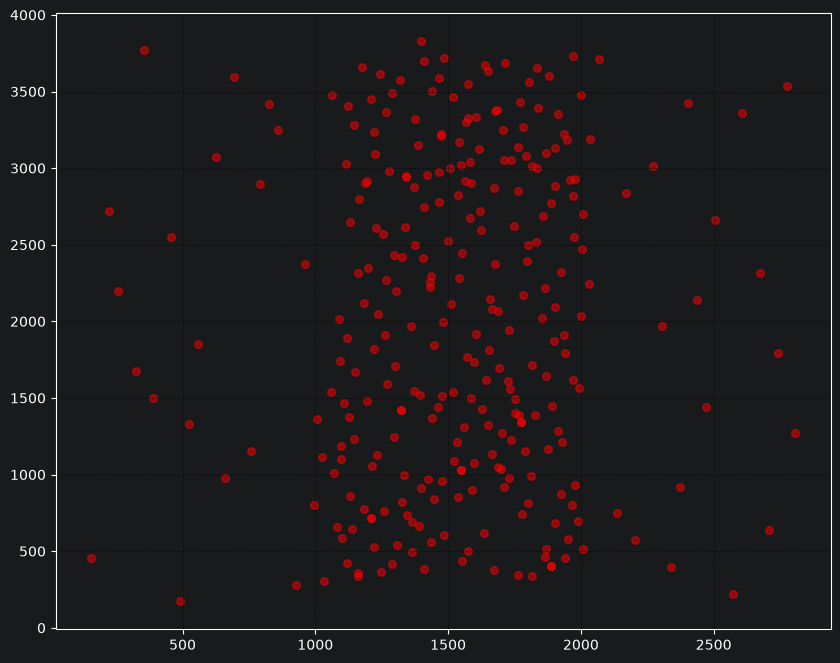

In [13]:
plt.figure(figsize=(10, 8))
plt.scatter(df["y"], df["x"], alpha=0.5, color="red", s=30)

plt.grid(True, linestyle="--", color="black")
plt.show()

In [14]:
df["round_x"] = df["x"].round(0)
df["round_y"] = df["y"].round(0)
df["round_z"] = df["z"].round(0)


df = df.drop_duplicates(subset=["round_x", "round_y", "round_z", "commissioned"], keep="first")

In [15]:
df.to_parquet(f"{save_file_path}wells.parquet", engine="pyarrow")

Series([], Name: well_id, dtype: str)